# Imports

In [1]:
import murraylab_tools.biotek as mt_biotek
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# from lmfit import Model
# from bioscrape.inference import py_inference

sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline

# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

# Functions

In [2]:
def Hill_rep_fun(x, params):
    '''
    Hill repression function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def Hill_act_fun(x, params):
    '''
    Hill activation function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b * np.exp(n*(np.log(x) - np.log(K))) / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a


In [3]:
def max_NOTNOT_FC(params1, params2):
    beta1, alpha1, K1, n1 = params1
    maxO2 = Hill_rep_fun(alpha1, params2)
    maxO1 = Hill_rep_fun(beta1+alpha1, params2)
    return maxO2/maxO1

In [13]:
def SP_composition_FC(params_s, params_p):
    b_s, a_s, K_s, n_s = params_s
    b_p, a_p, K_p, n_p = params_p

    O2 = Hill_rep_fun(a_s, params_p)
    O1 = Hill_rep_fun(b_s+a_s, params_p)

    return O2/O1

In [4]:
def plot_3_curves(x, params1, params2, pfactor1, pfactor2,
                  savefig='', xlim=None, ylim=None):
    xmin = np.min(x)*.6
    xmax = np.max(x)*2
    
    beta1, alpha1, K1, n1 = params1
    bf1, af1, Kf1, nf1 = pfactor1
    beta2, alpha2, K2, n2 = params2
    bf2, af2, Kf2, nf2 = pfactor2

    p1 = (beta1*bf1, alpha1*af1, K1*Kf1, n1*nf1)
    p2 = (beta2*bf2, alpha2*af2, K2*Kf2, n2*nf2)
    
    y1 = Hill_rep_fun(x, p1)
    y2 = Hill_rep_fun(x, p2)
    z = Hill_rep_fun(y1, p2)

    I1 = np.min(x)*3
    I2 = np.max(x)/3
    Z1 = Hill_rep_fun(I1, p1)
    Z2 = Hill_rep_fun(I2, p1)
    O1 = Hill_rep_fun(Z1, p2)
    O2 = Hill_rep_fun(Z2, p2)

    fig, ax = plt.subplots(1, 3, figsize=(10,3), sharex=True, sharey=True)
    ax[0].plot(x, y1, lw=10, c='b')
    ax[0].plot([I1,I1],[0,Z1], c='k', linestyle='--', lw=2)
    ax[0].plot([I1,1e4],[Z1, Z1], c='k', linestyle='--', lw=2)
    ax[0].plot([I2,I2],[0,Z2], c='k', linestyle='--', lw=2)
    ax[0].plot([I2,1e4],[Z2, Z2], c='k', linestyle='--', lw=2)
    ax[1].plot(x, y2, lw=10, c='r')
    ax[1].plot([Z1,Z1],[0,O1], c='k', linestyle='--', lw=2)
    ax[1].plot([Z1,1e4],[O1, O1], c='k', linestyle='--', lw=2)
    ax[1].plot([Z2,Z2],[0,O2], c='k', linestyle='--', lw=2)
    ax[1].plot([Z2,1e4],[O2, O2], c='k', linestyle='--', lw=2)
    ax[2].plot(x, z, lw=10, c='purple')
    ax[2].plot([I1,I1],[0,O1], c='k', linestyle='--', lw=2)
    ax[2].plot([I1,1e4],[O1, O1], c='k', linestyle='--', lw=2)
    ax[2].plot([I2,I2],[0,O2], c='k', linestyle='--', lw=2)
    ax[2].plot([I2,1e4],[O2, O2], c='k', linestyle='--', lw=2)

    if xlim != None:
        ax[0].set_xlim(xlim)
    if ylim != None:
        ax[0].set_ylim(ylim)
    ax[0].set_yscale('log')
    ax[0].set_xscale('log')

    # ax[0].set_xticks([np.min(x)*10, 1, np.max(x)/10])
    ax[1].yaxis.set_tick_params(labelleft=True)
    ax[2].yaxis.set_tick_params(labelleft=True)

    ax[0].set_xlabel('Input')
    ax[0].set_ylabel('Output')
    ax[1].set_xlabel('Input')
    ax[1].set_ylabel('Output')
    ax[2].set_xlabel('Input')
    ax[2].set_ylabel('Output')
    
    plt.tight_layout()
    if savefig != '':
        plt.savefig('./figs/'+savefig)
    
    plt.show()

    print(max_NOTNOT_FC(p1, p2))

# Fig 1 curves

## Reference NOT-NOT response

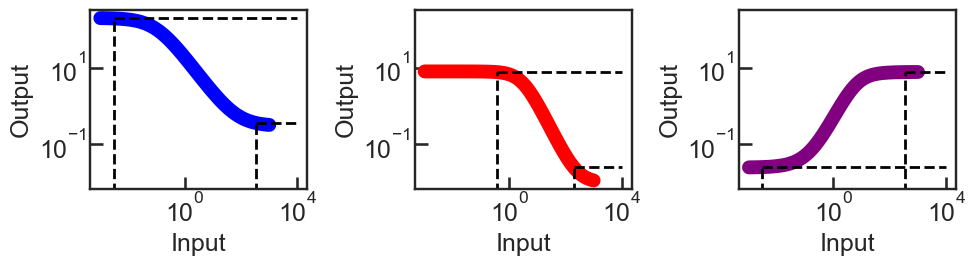

315.165817187835


In [5]:
x = np.logspace(-3,3,100)
xmin = 6e-4
xmax = 2e3
ymin = 6e-4
ymax = 2e3

beta = 2e2
alpha = 3e-1
K = 1e-1
n = 1

params1 = (beta, alpha, K, n)
pf1 = (1,1,1,1)

beta = 8
alpha = 1e-2
K = 3e0
n = 1.5

params2 = (beta, alpha, K, n)
pf2 = (1,1,1,1)

plot_3_curves(x, params1, params2, pf1, pf2, savefig='Fig1_NOTNOT_schematic.pdf')

## Change that preserves NOT-NOT functionality

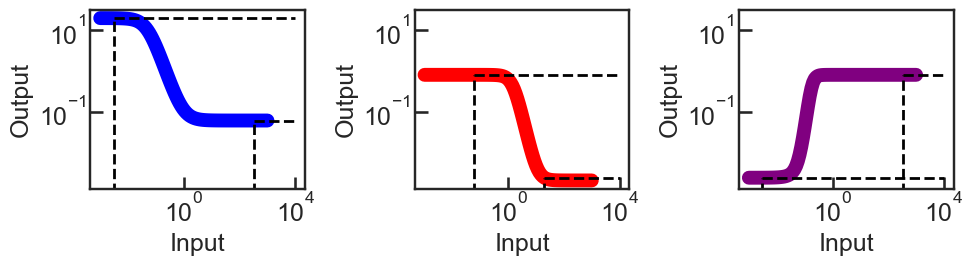

343.54400498659095


In [6]:
# a change that perserves response
pf = (1/10, 1/5, 1/2, 2)
pf1 = pf
pf2 = pf

plot_3_curves(x, params1, params2, pf1, pf2, savefig='Fig1_NOTNOT_changeworks.pdf')

In [7]:
343.544/315.165

1.0900448971173828

## Change that breaks NOT-NOT functionality

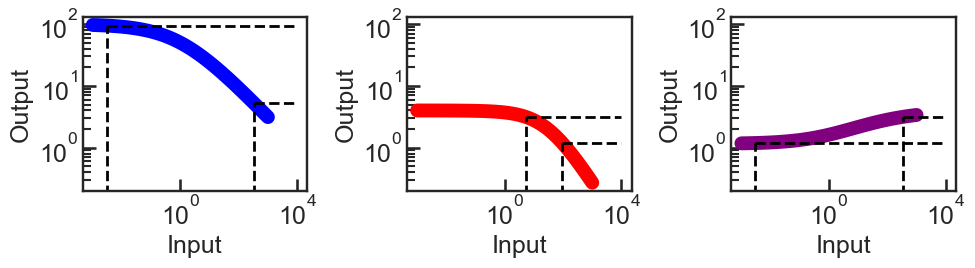

3.431345174298185


In [8]:
# change that breaks response
pf = (1/2, 1/5, 10, 1/2)
pf1 = pf
pf2 = pf

plot_3_curves(x, params1, params2, pf1, pf2, savefig='Fig1_NOTNOT_changebreaks.pdf')

In [9]:
315.165/3.43

91.88483965014578

In [10]:
3.43/315.165*100

1.0883188171275364

# Fig 6 curves

Stanton et al kindly provides Hill parameter fits for their repressor library. The two best repressors (by fold change) are SrpR and PhlF.

Note that they have a slightly different formulation where they use $y_{max}$ and $y_{min}$. Translating it to our formulation we would use $\beta = y_{max}-y_{min}$ and $\alpha = y_{min}$.

## Initial predicted NOT-NOT from Stanton parameters

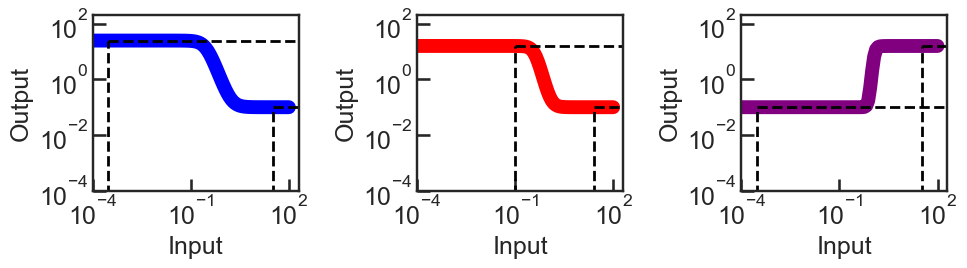

159.68984799782854


In [11]:
x = np.logspace(-4,2,100)
xmin = 6e-3
xmax = 2e2
ymin = 6e-3
ymax = 2e2

# SrpR (207-fold repression)
K_s = 0.3
n_s = 3.2
a_s = 0.1
b_s = 25-a_s

params_s = (b_s, a_s, K_s, n_s)
pf1 = (1,1,1,1)

# PhlF (197-fold repression)
K_p = 0.4
n_p = 4.5
a_p = 0.1
b_p = 16-a_p

params_p = (b_p, a_p, K_p, n_p)
pf2 = (1,1,1,1)

plot_3_curves(x, params_s, params_p, pf1, pf2,
              xlim=(1e-4,2e2),
              ylim=(1e-4,2e2),
              savefig='Fig6_Simulated_NOTNOT_active.pdf')



## Applying Growth Arrest transformation

Now we apply a 'growth arrest' transformation, by which we apply $\beta$ goes down 300X, $\alpha$ goes down 150X, $K$ is unchanged.

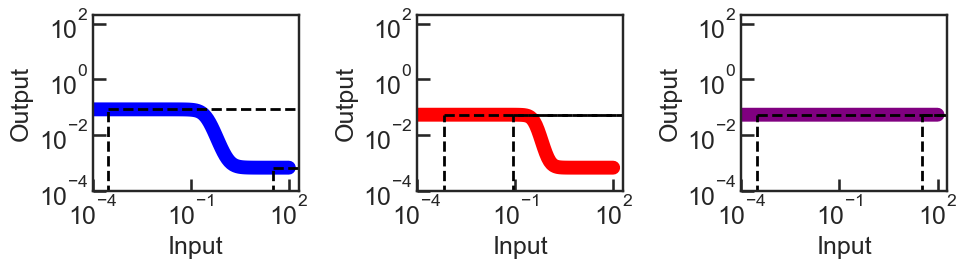

1.0008645351686631


In [12]:
params_s = (b_s, a_s, K_s, n_s)
pf1 = (1/300,1/150,1,1)

params_p = (b_p, a_p, K_p, n_p)
pf2 = (1/300,1/150,1,1)

plot_3_curves(x, params_s, params_p, pf1, pf2,
              ylim=(1e-4,2e2),
              xlim=(1e-4,2e2),
              savefig='Fig6_Simulated_NOTNOT_arrest.pdf')


## Calculation of correction factors to restore circuit function

Supplemental Fig. 25

First we confirm the FC calculation function correctly returns the original fold change value of the simulated Stanton circuit, with and without the growth arrest changes

In [15]:
# SrpR (207-fold repression)
K_s = 0.3
n_s = 3.2
a_s = 0.1
b_s = 25-a_s

params_s = (b_s, a_s, K_s, n_s)

# PhlF (197-fold repression)
K_p = 0.4
n_p = 4.5
a_p = 0.1
b_p = 16-a_p

params_p = (b_p, a_p, K_p, n_p)

print(SP_composition_FC(params_s, params_p))

159.68984799782854


In [16]:
# now apply growth arrest changes to all but beta

# SrpR (207-fold repression)
K_s = 0.3
n_s = 3.2
a_s = 0.1/150
b_s = (25-a_s)/300

params_s = (b_s, a_s, K_s, n_s)

# PhlF (197-fold repression)
K_p = 0.4
n_p = 4.5
a_p = 0.1/150
b_p = (16-a_p)/300

params_p = (b_p, a_p, K_p, n_p)

print(SP_composition_FC(params_s, params_p))

1.0008801062201957


Now we scale $\beta$ and $\alpha$ by a correction factor and plot the resulting fold response of the NOT-NOT circuit as a function of this correction factor

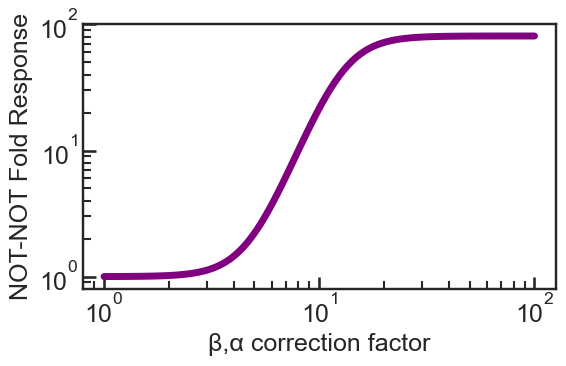

8.111308307896872

79.65686797931377
1.1335464761670588


In [17]:
beta_factor = np.logspace(0,2,100)
fc_ls = []
for bf in beta_factor:
    b_s_new = b_s * bf
    b_p_new = b_p * bf
    a_s_new = a_s * bf
    a_p_new = a_p * bf
    params_s = (b_s_new, a_s_new, K_s, n_s)
    params_p = (b_p_new, a_p_new, K_p, n_p)
    fc_ls.append(SP_composition_FC(params_s, params_p))

plt.figure(figsize=(6,4))
plt.plot(beta_factor, fc_ls, c='purple', lw=5)
plt.gca().set_xscale('log')
plt.gca().set_yscale('log')
# plt.axhline(1, linestyle='--', c='k')
plt.xlabel('β,α correction factor')
plt.ylabel('NOT-NOT Fold Response')
plt.tight_layout()
plt.savefig('./figs/Simulated_NOTNOT_beta_line.pdf')
plt.savefig('./figs/Simulated_NOTNOT_beta_line.png')
plt.show()

print(beta_factor[np.where(np.array(fc_ls) >= 10)[0][0]])

print()
print(fc_ls[np.where(beta_factor >= 30)[0][0]])
print(fc_ls[np.where(beta_factor >= 3)[0][0]])